[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HamadAlobeidliMAI/CVIP/blob/main/Notebooks/fisheye_project.ipynb)

# Distortion-Aware Object Detection for Fisheye Traffic Cameras
**Computer Vision and Image Processing – Course Project**

Hardware: NVIDIA GeForce RTX 4060 (8 GB), Windows, Python 3.12

**Setup** (run once in the VS Code terminal, inside the `.venv`):
```
python -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124
python -m pip install ultralytics opencv-python numpy pandas matplotlib huggingface_hub ipykernel
```
Run the cells from top to bottom. Steps that were already done (download, training) are skipped automatically.

## Setup

In [8]:
from pathlib import Path
from collections import Counter

import numpy as np
import torch

DATA_DIR = Path("data/fisheye8k")

## Step 0: Check the GPU

In [9]:
def check_gpu():
    print("PyTorch version:", torch.__version__)
    print("CUDA available: ", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU name:       ", torch.cuda.get_device_name(0))
        memory = torch.cuda.get_device_properties(0).total_memory / 1024**3
        print(f"GPU memory:      {memory:.1f} GB")
    else:
        print("GPU not found, training will be very slow.")

In [10]:
check_gpu()

PyTorch version: 2.6.0+cu124
CUDA available:  True
GPU name:        NVIDIA GeForce RTX 4060
GPU memory:      8.0 GB


## Step 1: Download the FishEye8K dataset

In [11]:
# The official download link (NCHC) is broken, so I use a copy of
# FishEye8K on Hugging Face: https://huggingface.co/datasets/hieupth/fisheye8k
# Only the images and the YOLO labels are downloaded (not the big zip files).
def download_dataset():
    from huggingface_hub import snapshot_download

    if any((DATA_DIR / "test" / "labels").glob("*.txt")):
        print("Dataset already downloaded:", DATA_DIR.resolve())
        return

    snapshot_download(
        repo_id="hieupth/fisheye8k",
        repo_type="dataset",
        local_dir=DATA_DIR,
        allow_patterns=["train/images/*", "train/labels/*",
                        "test/images/*", "test/labels/*"],
    )
    print("Download finished:", DATA_DIR.resolve())

In [12]:
download_dataset()

Dataset already downloaded: C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k


c:\Users\itsfr\Desktop\Master\fisheye-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 2: Check the dataset

In [13]:
# Counts images, label files and boxes per class, so I can compare
# them with the numbers in the paper (train 5288, test 2712 images).
def check_dataset():
    for split in ["train", "test"]:
        images = list((DATA_DIR / split / "images").glob("*"))
        labels = list((DATA_DIR / split / "labels").glob("*.txt"))

        class_counts = Counter()
        for label_file in labels:
            for line in label_file.read_text().splitlines():
                if line.strip():
                    class_counts[int(line.split()[0])] += 1

        print(f"\n--- {split} ---")
        print("Images:     ", len(images))
        print("Label files:", len(labels))
        print("Boxes:      ", sum(class_counts.values()))
        print("Boxes per class ID:", dict(sorted(class_counts.items())))

In [14]:
check_dataset()


--- train ---
Images:      5288
Label files: 5288
Boxes:       112213
Boxes per class ID: {0: 2054, 1: 62261, 2: 36636, 3: 9126, 4: 2136}

--- test ---
Images:      2712
Label files: 2712
Boxes:       45145
Boxes per class ID: {0: 930, 1: 26270, 2: 14113, 3: 2633, 4: 1199}


## Step 3: Create the dataset file for YOLOv8

In [15]:
# YOLOv8 needs a small .yaml file that says where the images are
# and what each class ID means. The class order was checked with
# check_dataset() and matches the official FishEye8K order.
CLASS_NAMES = ["Bus", "Bike", "Car", "Pedestrian", "Truck"]
DATA_YAML = DATA_DIR / "fisheye8k.yaml"


def create_yaml():
    text = (
        f"path: {DATA_DIR.resolve().as_posix()}\n"
        "train: train/images\n"
        "val: test/images\n"
        "names:\n"
    )
    for i, name in enumerate(CLASS_NAMES):
        text += f"  {i}: {name}\n"

    DATA_YAML.write_text(text)
    print("Created:", DATA_YAML)
    print(text)

In [16]:
create_yaml()

Created: data\fisheye8k\fisheye8k.yaml
path: C:/Users/itsfr/Desktop/Master/fisheye-project/data/fisheye8k
train: train/images
val: test/images
names:
  0: Bus
  1: Bike
  2: Car
  3: Pedestrian
  4: Truck



## Step 4: Train the YOLOv8 baseline (640x640)

*Takes about 7 hours. If `best.pt` already exists, this cell does nothing.*

In [17]:
# Same as the paper: YOLOv8 at input size 640.
# The paper has no validation set, only train and test, so the
# test set is used for validation (same as the paper).
# Results are saved in runs/fisheye8k/baseline_yolov8l
# Full path is used, otherwise Ultralytics saves inside runs/detect/
RUNS_DIR = Path("runs/fisheye8k").resolve()
BASELINE_WEIGHTS = RUNS_DIR / "baseline_yolov8l" / "weights" / "best.pt"


def train_baseline():
    from ultralytics import YOLO

    if BASELINE_WEIGHTS.exists():
        print("Already trained:", BASELINE_WEIGHTS)
        return

    last = RUNS_DIR / "baseline_yolov8l" / "weights" / "last.pt"
    if last.exists():
        # Continue training if it stopped before the end
        print("Resuming from:", last)
        model = YOLO(last)
        model.train(resume=True)
        return

    model = YOLO("yolov8l.pt")      # pre-trained on COCO
    model.train(
        data=str(DATA_YAML),
        imgsz=640,
        epochs=100,
        batch=8,                    # fits in 8 GB GPU memory
        workers=4,
        device=0,
        project=str(RUNS_DIR),
        name="baseline_yolov8l",
        seed=0,                     # same results if run again
    )

In [18]:
train_baseline()   # skipped if the model is already trained

Already trained: C:\Users\itsfr\Desktop\Master\fisheye-project\runs\fisheye8k\baseline_yolov8l\weights\best.pt


## Step 5: Evaluate the baseline on the test set

In [19]:
# Two evaluations:
#   1. Ultralytics default settings (conf=0.001, iou=0.7)
#   2. Paper settings (conf=0.5, iou=0.5), for a fair comparison
#      with Table 2 of the FishEye8K paper
# Results are saved in results/baseline_eval.csv
def evaluate_baseline():
    import pandas as pd
    from ultralytics import YOLO

    weights = BASELINE_WEIGHTS
    if not weights.exists():                  # use last.pt if best.pt is missing
        weights = weights.with_name("last.pt")
    print("Using weights:", weights)

    model = YOLO(weights)
    settings = {"default": dict(conf=0.001, iou=0.7),
                "paper":   dict(conf=0.5, iou=0.5)}

    rows = []
    for setting_name, params in settings.items():
        metrics = model.val(data=str(DATA_YAML), imgsz=640, batch=8,
                            device=0, split="val", plots=False, **params)
        box = metrics.box

        # Overall result
        rows.append({"setting": setting_name, "class": "all",
                     "precision": box.mp, "recall": box.mr,
                     "mAP50": box.map50, "mAP50_95": box.map})

        # Result for each class
        for i, class_id in enumerate(box.ap_class_index):
            rows.append({"setting": setting_name,
                         "class": CLASS_NAMES[class_id],
                         "precision": box.p[i], "recall": box.r[i],
                         "mAP50": box.ap50[i], "mAP50_95": box.ap[i]})

    table = pd.DataFrame(rows).round(4)
    Path("results").mkdir(exist_ok=True)
    table.to_csv("results/baseline_eval.csv", index=False)
    print(table.to_string(index=False))
    print("\nSaved: results/baseline_eval.csv")

In [20]:
evaluate_baseline()

Using weights: C:\Users\itsfr\Desktop\Master\fisheye-project\runs\fisheye8k\baseline_yolov8l\weights\best.pt
Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 112 layers, 43,610,463 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2232.5±296.6 MB/s, size: 1329.5 KB)
val: Scanning C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\test\labels.cache... 2712 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2712/2712  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 0/339  7.4s


KeyboardInterrupt: 

## Step 6: Radius-stratified evaluation (my main contribution)

In [ ]:
# The image is divided into 3 rings by the distance from the center:
#   rho = distance from image center / (half of the image size)
#   center: rho < 1/3,  middle: 1/3 <= rho < 2/3,  edge: rho >= 2/3
# Every ground-truth box and every predicted box is put in a ring
# using its box center. Then mAP is computed for each ring alone.
# Edge gap = mAP(center) - mAP(edge). Smaller gap = more robust.
RINGS = {"center": (0.0, 1 / 3), "middle": (1 / 3, 2 / 3), "edge": (2 / 3, 10.0)}
IOU_THRESHOLDS = np.linspace(0.5, 0.95, 10)
# np.trapz was renamed to np.trapezoid in NumPy 2
trapezoid = getattr(np, "trapezoid", None) or np.trapz


def box_iou(a, b):
    """IoU between every box in a (N,4) and b (M,4), format x1,y1,x2,y2."""
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def match_predictions(gt_boxes, pred_boxes):
    """For each IoU threshold, mark which predictions are correct (True Positive).
    Same matching method as Ultralytics: highest IoU pairs are matched first,
    and each ground truth can only be matched once."""
    correct = np.zeros((len(pred_boxes), len(IOU_THRESHOLDS)), dtype=bool)
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        return correct
    iou = box_iou(gt_boxes, pred_boxes)
    for t, threshold in enumerate(IOU_THRESHOLDS):
        matches = np.argwhere(iou >= threshold)          # (gt, pred) pairs
        if len(matches) == 0:
            continue
        order = iou[matches[:, 0], matches[:, 1]].argsort()[::-1]
        matches = matches[order]
        matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
        matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
        correct[matches[:, 1], t] = True
    return correct


def average_precision(correct, conf, n_gt):
    """AP for one class (101-point interpolation, same as Ultralytics/COCO).
    Returns one AP value for each IoU threshold."""
    if n_gt == 0:
        return None
    if len(conf) == 0:
        return np.zeros(len(IOU_THRESHOLDS))
    order = np.argsort(-conf)
    tp = np.cumsum(correct[order], axis=0)
    fp = np.cumsum(~correct[order], axis=0)
    recall = tp / n_gt
    precision = tp / (tp + fp)

    ap = np.zeros(len(IOU_THRESHOLDS))
    x = np.linspace(0, 1, 101)
    for t in range(len(IOU_THRESHOLDS)):
        mrec = np.concatenate(([0.0], recall[:, t], [1.0]))
        mpre = np.concatenate(([1.0], precision[:, t], [0.0]))
        mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))   # make it decreasing
        ap[t] = trapezoid(np.interp(x, mrec, mpre), x)
    return ap


def ring_of(cx, cy):
    """Ring name for normalized box centers (0..1). Images are square."""
    rho = np.sqrt((cx - 0.5) ** 2 + (cy - 0.5) ** 2) / 0.5
    names = np.empty(len(rho), dtype=object)
    for ring, (low, high) in RINGS.items():
        names[(rho >= low) & (rho < high)] = ring
    return names


def predict_test_set(weights, cache_file):
    """Run the model on all test images and save the predictions to a CSV,
    so the slow part only runs once."""
    import pandas as pd

    if Path(cache_file).exists():
        print("Loading saved predictions:", cache_file)
        return pd.read_csv(cache_file)

    from ultralytics import YOLO
    model = YOLO(weights)
    rows = []
    results = model.predict(source=str(DATA_DIR / "test" / "images"), imgsz=640,
                            conf=0.001, iou=0.7, max_det=300, device=0,
                            stream=True, verbose=False)
    for i, result in enumerate(results):
        image = Path(result.path).stem
        boxes = result.boxes
        for (x1, y1, x2, y2), c, s in zip(boxes.xyxyn.cpu().numpy(),
                                          boxes.cls.cpu().numpy(),
                                          boxes.conf.cpu().numpy()):
            rows.append((image, int(c), float(s), x1, y1, x2, y2))
        if (i + 1) % 500 == 0:
            print(f"  predicted {i + 1} images")

    preds = pd.DataFrame(rows, columns=["image", "cls", "conf",
                                        "x1", "y1", "x2", "y2"])
    Path(cache_file).parent.mkdir(exist_ok=True)
    preds.to_csv(cache_file, index=False)
    print("Saved predictions:", cache_file)
    return preds


def load_ground_truth():
    """Read the YOLO label files of the test set (normalized x1,y1,x2,y2)."""
    import pandas as pd

    rows = []
    for label_file in (DATA_DIR / "test" / "labels").glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                c, x, y, w, h = map(float, line.split())
                rows.append((label_file.stem, int(c),
                             x - w / 2, y - h / 2, x + w / 2, y + h / 2))
    return pd.DataFrame(rows, columns=["image", "cls", "x1", "y1", "x2", "y2"])


def radius_evaluation(weights=BASELINE_WEIGHTS, name="baseline"):
    import pandas as pd

    if not Path(weights).exists():
        weights = Path(weights).with_name("last.pt")

    preds = predict_test_set(weights, f"results/{name}_predictions.csv")
    gt = load_ground_truth()

    # Put every box in a ring using its center
    gt["ring"] = ring_of((gt.x1 + gt.x2) / 2, (gt.y1 + gt.y2) / 2)
    preds["ring"] = ring_of((preds.x1 + preds.x2) / 2, (preds.y1 + preds.y2) / 2)
    gt["area"] = (gt.x2 - gt.x1) * (gt.y2 - gt.y1)

    rows = []
    for ring in ["all"] + list(RINGS):
        g_ring = gt if ring == "all" else gt[gt.ring == ring]
        p_ring = preds if ring == "all" else preds[preds.ring == ring]

        class_aps = []
        for class_id, class_name in enumerate(CLASS_NAMES):
            g = g_ring[g_ring.cls == class_id]
            p = p_ring[p_ring.cls == class_id]

            # Match predictions to ground truth image by image
            correct, conf = [], []
            g_groups = dict(tuple(g.groupby("image")))
            for image, p_img in p.groupby("image"):
                g_img = g_groups.get(image)
                g_boxes = g_img[["x1", "y1", "x2", "y2"]].to_numpy() if g_img is not None else np.zeros((0, 4))
                correct.append(match_predictions(g_boxes, p_img[["x1", "y1", "x2", "y2"]].to_numpy()))
                conf.append(p_img.conf.to_numpy())
            correct = np.concatenate(correct) if correct else np.zeros((0, 10), dtype=bool)
            conf = np.concatenate(conf) if conf else np.zeros(0)

            ap = average_precision(correct, conf, len(g))
            if ap is None:
                continue
            class_aps.append(ap)
            rows.append({"ring": ring, "class": class_name, "n_gt": len(g),
                         "mAP50": ap[0], "mAP50_95": ap.mean()})

        mean_ap = np.mean(class_aps, axis=0)
        rows.append({"ring": ring, "class": "all", "n_gt": len(g_ring),
                     "mAP50": mean_ap[0], "mAP50_95": mean_ap.mean(),
                     "mean_box_area_%": 100 * g_ring.area.mean()})

    table = pd.DataFrame(rows).round(4)
    table.to_csv(f"results/{name}_radius_eval.csv", index=False)

    summary = table[table["class"] == "all"]
    print("\n=== Radius-stratified evaluation:", name, "===")
    print(summary.to_string(index=False))
    m = summary.set_index("ring")
    print(f"\nEdge gap (mAP50):     {m.loc['center', 'mAP50'] - m.loc['edge', 'mAP50']:.4f}")
    print(f"Edge gap (mAP50-95):  {m.loc['center', 'mAP50_95'] - m.loc['edge', 'mAP50_95']:.4f}")
    print("\nPer-class results saved in:", f"results/{name}_radius_eval.csv")

In [ ]:
radius_evaluation()

Loading saved predictions: results/baseline_predictions.csv

=== Radius-stratified evaluation: baseline ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_area_%
   all   all 45145 0.5309    0.3183           0.2655
center   all   426 0.8049    0.5940           1.3181
middle   all  9203 0.5828    0.3997           0.5435
  edge   all 35516 0.5187    0.2956           0.1808

Edge gap (mAP50):     0.2862
Edge gap (mAP50-95):  0.2984

Per-class results saved in: results/baseline_radius_eval.csv


## Step 7: Download VisDrone (normal drone images)

In [ ]:
# VisDrone2019-DET train set: 6471 drone images of roads, taken from
# above, similar to the view of a fisheye traffic camera.
VISDRONE_DIR = Path("data/visdrone")
SYNTH_DIR = Path("data/synthetic_fisheye")


def download_visdrone():
    from ultralytics.utils.downloads import download

    if (VISDRONE_DIR / "VisDrone2019-DET-train" / "images").exists():
        print("VisDrone already downloaded:", VISDRONE_DIR.resolve())
        return

    url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip"
    download(url, dir=VISDRONE_DIR, unzip=True, delete=True)
    print("VisDrone downloaded to:", VISDRONE_DIR.resolve())


# VisDrone class IDs -> FishEye8K class IDs (0 Bus, 1 Bike, 2 Car, 3 Pedestrian, 4 Truck)
# Classes that do not exist in FishEye8K (tricycle, others, ignored) are removed.
VISDRONE_TO_FISHEYE = {
    1: 3,   # pedestrian      -> Pedestrian
    2: 3,   # people          -> Pedestrian
    3: 1,   # bicycle         -> Bike
    10: 1,  # motor           -> Bike  (scooters, like in FishEye8K)
    4: 2,   # car             -> Car
    5: 2,   # van             -> Car
    6: 4,   # truck           -> Truck
    9: 0,   # bus             -> Bus
}


def read_visdrone_boxes(annotation_file):
    """VisDrone format per line: x, y, w, h, score, category, truncation, occlusion
    (pixels). Returns a list of (fisheye_class, x1, y1, x2, y2)."""
    boxes = []
    for line in annotation_file.read_text().splitlines():
        values = [int(v) for v in line.strip().strip(",").split(",")[:6]]
        if len(values) < 6:
            continue
        x, y, w, h, score, category = values
        if score == 0 or category not in VISDRONE_TO_FISHEYE:
            continue                       # score 0 = ignored region
        boxes.append((VISDRONE_TO_FISHEYE[category], x, y, x + w, y + h))
    return boxes

In [ ]:
download_visdrone()

VisDrone already downloaded: C:\Users\itsfr\Desktop\Master\fisheye-project\data\visdrone


## Step 8: Create synthetic fisheye images

In [ ]:
# Equidistant fisheye model: r_d = f_d * theta
# Normal (pinhole) camera:   r_u = f_u * tan(theta)
# For each pixel of the new fisheye image, find its angle theta, then
# take the pixel from the normal image at distance r_u (same direction).
# theta_max (half of the field of view) is random for every image,
# so the distortion strength changes from image to image.
SYNTH_SIZE = 960                     # output image size (square)
N_SYNTH = 3000                       # number of synthetic images to create


def fisheye_maps(src_w, src_h, theta_max):
    """Build the pixel maps for cv2.remap (fisheye pixel -> source pixel)."""
    R = SYNTH_SIZE / 2                     # radius of the fisheye circle
    f_d = R / theta_max                    # fisheye focal length
    f_u = (max(src_w, src_h) / 2) / np.tan(theta_max)   # source fills the circle

    ys, xs = np.mgrid[0:SYNTH_SIZE, 0:SYNTH_SIZE].astype(np.float32)
    dx, dy = xs - R, ys - R
    r_d = np.sqrt(dx ** 2 + dy ** 2)
    theta = r_d / f_d
    r_u = f_u * np.tan(np.clip(theta, 0, np.radians(89)))
    scale = np.where(r_d > 0, r_u / np.maximum(r_d, 1e-6), 0)

    map_x = (src_w / 2 + dx * scale).astype(np.float32)
    map_y = (src_h / 2 + dy * scale).astype(np.float32)
    outside = r_d > R                      # outside the fisheye circle -> black
    map_x[outside] = -1
    map_y[outside] = -1
    return map_x, map_y, f_d, f_u


def source_to_fisheye(px, py, src_w, src_h, f_d, f_u):
    """Move points from the normal image to the fisheye image (for the boxes)."""
    dx, dy = px - src_w / 2, py - src_h / 2
    r_u = np.sqrt(dx ** 2 + dy ** 2)
    theta = np.arctan(r_u / f_u)
    r_d = f_d * theta
    scale = np.where(r_u > 0, r_d / np.maximum(r_u, 1e-6), 0)
    R = SYNTH_SIZE / 2
    return R + dx * scale, R + dy * scale


def warp_box(x1, y1, x2, y2, src_w, src_h, f_d, f_u, n=10):
    """Warp points along the 4 edges of a box and take the smallest
    normal box that contains them."""
    t = np.linspace(0, 1, n)
    px = np.concatenate([x1 + (x2 - x1) * t, np.full(n, x2), x2 - (x2 - x1) * t, np.full(n, x1)])
    py = np.concatenate([np.full(n, y1), y1 + (y2 - y1) * t, np.full(n, y2), y2 - (y2 - y1) * t])
    fx, fy = source_to_fisheye(px, py, src_w, src_h, f_d, f_u)
    return fx.min(), fy.min(), fx.max(), fy.max()


def create_synthetic_fisheye():
    import cv2

    if len(list((SYNTH_DIR / "labels").glob("*.txt"))) >= N_SYNTH:
        print("Synthetic images already created:", SYNTH_DIR.resolve())
        return

    images_dir = SYNTH_DIR / "images"
    labels_dir = SYNTH_DIR / "labels"
    images_dir.mkdir(parents=True, exist_ok=True)
    labels_dir.mkdir(parents=True, exist_ok=True)

    source_images = sorted((VISDRONE_DIR / "VisDrone2019-DET-train" / "images").glob("*.jpg"))
    rng = np.random.default_rng(0)                      # same images every time
    chosen = rng.choice(len(source_images), size=min(N_SYNTH, len(source_images)), replace=False)

    R = SYNTH_SIZE / 2
    total_boxes = 0
    for k, idx in enumerate(chosen):
        image_path = source_images[idx]
        annotation = image_path.parent.parent / "annotations" / (image_path.stem + ".txt")
        image = cv2.imread(str(image_path))
        src_h, src_w = image.shape[:2]

        theta_max = np.radians(rng.uniform(60, 85))     # random distortion strength
        map_x, map_y, f_d, f_u = fisheye_maps(src_w, src_h, theta_max)
        fisheye = cv2.remap(image, map_x, map_y, cv2.INTER_LINEAR,
                            borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        lines = []
        for c, x1, y1, x2, y2 in read_visdrone_boxes(annotation):
            fx1, fy1, fx2, fy2 = warp_box(x1, y1, x2, y2, src_w, src_h, f_d, f_u)
            cx, cy = (fx1 + fx2) / 2, (fy1 + fy2) / 2
            if np.hypot(cx - R, cy - R) > R:            # center outside the circle
                continue
            fx1, fy1 = max(fx1, 0), max(fy1, 0)
            fx2, fy2 = min(fx2, SYNTH_SIZE), min(fy2, SYNTH_SIZE)
            w, h = fx2 - fx1, fy2 - fy1
            if w < 3 or h < 3:                          # too small after warping
                continue
            lines.append(f"{c} {(fx1 + w / 2) / SYNTH_SIZE:.6f} {(fy1 + h / 2) / SYNTH_SIZE:.6f} "
                         f"{w / SYNTH_SIZE:.6f} {h / SYNTH_SIZE:.6f}")

        name = f"synth_{image_path.stem}"
        cv2.imwrite(str(images_dir / f"{name}.jpg"), fisheye, [cv2.IMWRITE_JPEG_QUALITY, 95])
        (labels_dir / f"{name}.txt").write_text("\n".join(lines))
        total_boxes += len(lines)
        if (k + 1) % 250 == 0:
            print(f"  created {k + 1}/{len(chosen)} images")

    print(f"Done: {len(chosen)} images, {total_boxes} boxes in {SYNTH_DIR.resolve()}")


def preview_synthetic(n=6):
    """Draw the boxes on a few synthetic images and save one picture,
    to check that the boxes are in the right place."""
    import cv2

    colors = [(0, 165, 255), (255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 0, 255)]
    images = sorted((SYNTH_DIR / "images").glob("*.jpg"))[:n]
    tiles = []
    for image_path in images:
        image = cv2.imread(str(image_path))
        label = SYNTH_DIR / "labels" / (image_path.stem + ".txt")
        for line in label.read_text().splitlines():
            c, x, y, w, h = map(float, line.split())
            x1, y1 = int((x - w / 2) * SYNTH_SIZE), int((y - h / 2) * SYNTH_SIZE)
            x2, y2 = int((x + w / 2) * SYNTH_SIZE), int((y + h / 2) * SYNTH_SIZE)
            cv2.rectangle(image, (x1, y1), (x2, y2), colors[int(c)], 2)
        tiles.append(cv2.resize(image, (480, 480)))

    rows = [np.hstack(tiles[i:i + 3]) for i in range(0, len(tiles), 3)]
    Path("results").mkdir(exist_ok=True)
    cv2.imwrite("results/synthetic_examples.jpg", np.vstack(rows))
    print("Saved: results/synthetic_examples.jpg  (orange=Bus, blue=Bike, green=Car, red=Pedestrian, pink=Truck)")

In [ ]:
create_synthetic_fisheye()
preview_synthetic()

Synthetic images already created: C:\Users\itsfr\Desktop\Master\fisheye-project\data\synthetic_fisheye
Saved: results/synthetic_examples.jpg  (orange=Bus, blue=Bike, green=Car, red=Pedestrian, pink=Truck)


## Step 9: Train YOLOv8 with FishEye8K + synthetic fisheye images

*Training takes about 10 hours. If `best.pt` already exists, it is skipped.*

In [ ]:
# Same settings as the baseline (YOLOv8l, 640, 100 epochs, COCO weights),
# the only difference is the extra synthetic training images.
# The test set is the same real FishEye8K test set.
SYNTH_YAML = DATA_DIR / "fisheye8k_synthetic.yaml"
SYNTH_WEIGHTS = RUNS_DIR / "synthetic_yolov8l" / "weights" / "best.pt"


def train_synthetic():
    from ultralytics import YOLO

    text = (
        "train:\n"
        f"  - {(DATA_DIR / 'train' / 'images').resolve().as_posix()}\n"
        f"  - {(SYNTH_DIR / 'images').resolve().as_posix()}\n"
        f"val: {(DATA_DIR / 'test' / 'images').resolve().as_posix()}\n"
        "names:\n"
    )
    for i, name in enumerate(CLASS_NAMES):
        text += f"  {i}: {name}\n"
    SYNTH_YAML.write_text(text)

    if SYNTH_WEIGHTS.exists():
        print("Already trained:", SYNTH_WEIGHTS)
        return

    last = RUNS_DIR / "synthetic_yolov8l" / "weights" / "last.pt"
    if last.exists():
        print("Resuming from:", last)
        YOLO(last).train(resume=True)
        return

    model = YOLO("yolov8l.pt")
    model.train(
        data=str(SYNTH_YAML),
        imgsz=640,
        epochs=100,
        batch=8,
        workers=4,
        device=0,
        project=str(RUNS_DIR),
        name="synthetic_yolov8l",
        seed=0,
    )

In [ ]:
train_synthetic()   # skipped if the model is already trained

Already trained: C:\Users\itsfr\Desktop\Master\fisheye-project\runs\fisheye8k\synthetic_yolov8l\weights\best.pt


In [ ]:
radius_evaluation(SYNTH_WEIGHTS, name="synthetic")

Loading saved predictions: results/synthetic_predictions.csv

=== Radius-stratified evaluation: synthetic ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_area_%
   all   all 45145 0.5834    0.3316           0.2655
center   all   426 0.9141    0.6580           1.3181
middle   all  9203 0.5795    0.3920           0.5435
  edge   all 35516 0.5845    0.3135           0.1808

Edge gap (mAP50):     0.3296
Edge gap (mAP50-95):  0.3445

Per-class results saved in: results/synthetic_radius_eval.csv


## Step 10: Control experiment - baseline with the same training steps

*Training takes about 9 hours. If `best.pt` already exists, it is skipped.*

In [ ]:
# The synthetic model saw 8288 images per epoch, the baseline only 5288.
# So 100 synthetic epochs = 100 * 8288 / 5288 = about 157 baseline epochs.
# If this model is still worse than the synthetic model, the gain comes
# from the synthetic images and not only from longer training.
LONG_WEIGHTS = RUNS_DIR / "baseline_157ep_yolov8l" / "weights" / "best.pt"


def train_baseline_long():
    from ultralytics import YOLO

    if LONG_WEIGHTS.exists():
        print("Already trained:", LONG_WEIGHTS)
        return

    last = RUNS_DIR / "baseline_157ep_yolov8l" / "weights" / "last.pt"
    if last.exists():
        print("Resuming from:", last)
        YOLO(last).train(resume=True)
        return

    model = YOLO("yolov8l.pt")
    model.train(
        data=str(DATA_YAML),
        imgsz=640,
        epochs=157,
        batch=8,
        workers=4,
        device=0,
        project=str(RUNS_DIR),
        name="baseline_157ep_yolov8l",
        seed=0,
    )

In [ ]:
train_baseline_long()   # skipped if the model is already trained

Already trained: C:\Users\itsfr\Desktop\Master\fisheye-project\runs\fisheye8k\baseline_157ep_yolov8l\weights\best.pt


In [ ]:
radius_evaluation(LONG_WEIGHTS, name="baseline_157ep")

Loading saved predictions: results/baseline_157ep_predictions.csv

=== Radius-stratified evaluation: baseline_157ep ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_area_%
   all   all 45145 0.5142    0.2989           0.2655
center   all   426 0.8250    0.5934           1.3181
middle   all  9203 0.5888    0.3930           0.5435
  edge   all 35516 0.4884    0.2686           0.1808

Edge gap (mAP50):     0.3366
Edge gap (mAP50-95):  0.3248

Per-class results saved in: results/baseline_157ep_radius_eval.csv


## Step 11: Virtual pinhole rectification

*Rectifying all test images takes about 15–20 minutes. If the predictions are already saved, it is skipped.*

In [ ]:
# Instead of learning the distortion, remove it before detection.
# The fisheye image is split into 9 normal (pinhole) views:
#   1 view looking straight down at the center
#   8 views tilted towards the edge, every 45 degrees around the circle
# Each view looks like an image from a normal camera. The baseline model
# runs on every view, the boxes are moved back to the fisheye image,
# and duplicates are removed.
#
# Fisheye model: FishEye8K has no calibration data, so I assume the
# equidistant model (r = f * theta) with a 180 degree field of view
# filling the image circle (radius = half the image size).
VIEW_SIZE = 640                      # each pinhole view is 640x640
VIEW_FOV = np.radians(90)            # field of view of each pinhole view
EDGE_TILT = np.radians(60)           # how far the edge views look from the center
N_EDGE_VIEWS = 8


def view_rotations():
    """Rotation matrix for each view. Each matrix turns the pinhole camera
    so it looks in a different direction inside the fisheye hemisphere."""
    rotations = [np.eye(3)]                               # center view
    for k in range(N_EDGE_VIEWS):
        a = 2 * np.pi * k / N_EDGE_VIEWS                  # direction around the circle
        t = EDGE_TILT
        rot_z = np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
        rot_y = np.array([[np.cos(t), 0, np.sin(t)], [0, 1, 0], [-np.sin(t), 0, np.cos(t)]])
        # rot_z.T at the end removes the extra spin, so every view keeps the
        # same "up" direction as the fisheye image. Without it, the diagonal
        # views were turned 45 degrees and the boxes became twice too big
        # (found with box_shape_test, version 1 of the rectification).
        rotations.append(rot_z @ rot_y @ rot_z.T)
    return rotations


VIEW_ROTATIONS = view_rotations()
VIEW_AXES = np.array([r @ np.array([0, 0, 1.0]) for r in VIEW_ROTATIONS])


def view_to_fisheye(u, v, rotation, width, height):
    """Pixel (u, v) in a pinhole view -> pixel (x, y) in the fisheye image."""
    f_view = (VIEW_SIZE / 2) / np.tan(VIEW_FOV / 2)
    rays = np.stack([(u - VIEW_SIZE / 2) / f_view,
                     (v - VIEW_SIZE / 2) / f_view,
                     np.ones_like(u, dtype=np.float64)], axis=-1)
    d = rays @ rotation.T                                 # turn the ray into the fisheye frame
    theta = np.arccos(np.clip(d[..., 2] / np.linalg.norm(d, axis=-1), -1, 1))
    phi = np.arctan2(d[..., 1], d[..., 0])
    radius = min(width, height) / 2
    f_fish = radius / (np.pi / 2)                         # equidistant, 180 degree FOV
    r = f_fish * theta
    return width / 2 + r * np.cos(phi), height / 2 + r * np.sin(phi), d


_map_cache = {}


def view_maps(width, height):
    """Pixel maps for cv2.remap, one per view (saved for each image size)."""
    if (width, height) not in _map_cache:
        v, u = np.mgrid[0:VIEW_SIZE, 0:VIEW_SIZE].astype(np.float64)
        maps = []
        for rotation in VIEW_ROTATIONS:
            x, y, _ = view_to_fisheye(u, v, rotation, width, height)
            maps.append((x.astype(np.float32), y.astype(np.float32)))
        _map_cache[(width, height)] = maps
    return _map_cache[(width, height)]


def make_views(image):
    import cv2
    height, width = image.shape[:2]
    return [cv2.remap(image, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
            for mx, my in view_maps(width, height)]


def box_view_to_fisheye(x1, y1, x2, y2, view_index, width, height, n=10):
    """Move a box from a pinhole view back to the fisheye image.
    Returns the fisheye box and the index of the view whose direction is
    closest to the box center (used to remove duplicates)."""
    t = np.linspace(0, 1, n)
    u = np.concatenate([x1 + (x2 - x1) * t, np.full(n, x2), x2 - (x2 - x1) * t, np.full(n, x1)])
    v = np.concatenate([np.full(n, y1), y1 + (y2 - y1) * t, np.full(n, y2), y2 - (y2 - y1) * t])
    rotation = VIEW_ROTATIONS[view_index]
    fx, fy, _ = view_to_fisheye(u, v, rotation, width, height)
    _, _, d = view_to_fisheye(np.array([(x1 + x2) / 2]), np.array([(y1 + y2) / 2]),
                              rotation, width, height)
    d = d[0] / np.linalg.norm(d[0])
    closest_view = int(np.argmax(VIEW_AXES @ d))
    box = (max(fx.min(), 0), max(fy.min(), 0), min(fx.max(), width), min(fy.max(), height))
    return box, closest_view


def save_views_example():
    """Save one fisheye image and its 9 pinhole views (figure for the report)."""
    import cv2
    image_path = sorted((DATA_DIR / "test" / "images").glob("*"))[0]
    image = cv2.imread(str(image_path))
    views = make_views(image)
    small = [cv2.resize(v, (320, 320)) for v in views]
    # Order the 8 edge views around the center view in a 3x3 grid
    #   grid position:  view index (edge views go every 45 degrees, 0 = right)
    order = [[6, 7, 8], [5, 0, 1], [4, 3, 2]]
    grid = np.vstack([np.hstack([small[i] for i in row]) for row in order])
    original = cv2.resize(image, (960, 960))
    Path("results").mkdir(exist_ok=True)
    cv2.imwrite("results/rectified_views_example_v2.jpg", np.hstack([original, grid]))
    print("Saved: results/rectified_views_example_v2.jpg (left: fisheye, right: 9 pinhole views)")


def rectified_predictions(weights=BASELINE_WEIGHTS, name="rectified"):
    """Run the model on the 9 pinhole views of every test image, move the
    boxes back to the fisheye image, remove duplicates, and save the
    predictions in the same format as predict_test_set()."""
    import time
    import cv2
    import pandas as pd
    import torch as th
    from torchvision.ops import batched_nms
    from ultralytics import YOLO

    if Path(f"results/{name}_predictions.csv").exists():
        print("Rectified predictions already saved:", f"results/{name}_predictions.csv")
        return

    if not Path(weights).exists():
        weights = Path(weights).with_name("last.pt")
    model = YOLO(weights)

    image_paths = sorted((DATA_DIR / "test" / "images").glob("*"))
    rows = []
    start = time.time()
    for i, image_path in enumerate(image_paths):
        image = cv2.imread(str(image_path))
        height, width = image.shape[:2]
        views = make_views(image)
        results = model.predict(views, imgsz=VIEW_SIZE, conf=0.001, iou=0.7,
                                max_det=300, device=0, verbose=False)

        boxes, scores, classes = [], [], []
        for view_index, result in enumerate(results):
            for (x1, y1, x2, y2), c, s in zip(result.boxes.xyxy.cpu().numpy(),
                                              result.boxes.cls.cpu().numpy(),
                                              result.boxes.conf.cpu().numpy()):
                box, closest = box_view_to_fisheye(x1, y1, x2, y2, view_index, width, height)
                if closest != view_index:      # this object belongs to another view
                    continue
                if box[2] - box[0] < 2 or box[3] - box[1] < 2:
                    continue
                boxes.append(box)
                scores.append(s)
                classes.append(int(c))

        if boxes:
            b = th.tensor(boxes, dtype=th.float32)
            keep = batched_nms(b, th.tensor(scores), th.tensor(classes), 0.6)[:300].numpy()
            for k in keep:
                x1, y1, x2, y2 = boxes[k]
                rows.append((image_path.stem, classes[k], float(scores[k]),
                             x1 / width, y1 / height, x2 / width, y2 / height))
        if (i + 1) % 250 == 0:
            print(f"  rectified {i + 1}/{len(image_paths)} images")

    seconds = time.time() - start
    ms_per_image = 1000 * seconds / len(image_paths)
    print(f"Rectification pipeline: {ms_per_image:.1f} ms per image ({1000 / ms_per_image:.1f} FPS)")

    preds = pd.DataFrame(rows, columns=["image", "cls", "conf", "x1", "y1", "x2", "y2"])
    preds.to_csv(f"results/{name}_predictions.csv", index=False)
    Path(f"results/{name}_speed.txt").write_text(
        f"{ms_per_image:.2f} ms per image, {1000 / ms_per_image:.2f} FPS, "
        f"{len(image_paths)} images, {len(VIEW_ROTATIONS)} views per image\n")
    print("Saved:", f"results/{name}_predictions.csv")


def fused_predictions(name="fused", base="baseline", rect="rectified"):
    """Combine the normal fisheye predictions with the rectified predictions
    and remove duplicates. Idea: keep the good center results from the
    fisheye image and add the rectified results at the edge."""
    import pandas as pd
    import torch as th
    from torchvision.ops import batched_nms

    preds = pd.concat([pd.read_csv(f"results/{base}_predictions.csv"),
                       pd.read_csv(f"results/{rect}_predictions.csv")])
    rows = []
    for image, p in preds.groupby("image"):
        b = th.tensor(p[["x1", "y1", "x2", "y2"]].to_numpy(), dtype=th.float32)
        keep = batched_nms(b, th.tensor(p.conf.to_numpy(), dtype=th.float32),
                           th.tensor(p.cls.to_numpy()), 0.6)[:300].numpy()
        rows.append(p.iloc[keep])
    pd.concat(rows).to_csv(f"results/{name}_predictions.csv", index=False)
    print("Saved:", f"results/{name}_predictions.csv")

In [ ]:
save_views_example()

Saved: results/rectified_views_example_v2.jpg (left: fisheye, right: 9 pinhole views)


In [ ]:
rectified_predictions(name="rectified_v2")   # skipped if already saved
radius_evaluation(name="rectified_v2")

Rectified predictions already saved: results/rectified_v2_predictions.csv
Loading saved predictions: results/rectified_v2_predictions.csv

=== Radius-stratified evaluation: rectified_v2 ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_area_%
   all   all 45145 0.4340    0.2013           0.2655
center   all   426 0.5424    0.3027           1.3181
middle   all  9203 0.4751    0.2476           0.5435
  edge   all 35516 0.4151    0.1843           0.1808

Edge gap (mAP50):     0.1273
Edge gap (mAP50-95):  0.1184

Per-class results saved in: results/rectified_v2_radius_eval.csv


In [ ]:
fused_predictions(name="fused_v2", rect="rectified_v2")
radius_evaluation(name="fused_v2")

Saved: results/fused_v2_predictions.csv
Loading saved predictions: results/fused_v2_predictions.csv

=== Radius-stratified evaluation: fused_v2 ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_area_%
   all   all 45145 0.5220    0.2856           0.2655
center   all   426 0.7708    0.5515           1.3181
middle   all  9203 0.5578    0.3445           0.5435
  edge   all 35516 0.5059    0.2648           0.1808

Edge gap (mAP50):     0.2649
Edge gap (mAP50-95):  0.2867

Per-class results saved in: results/fused_v2_radius_eval.csv


## Step 12: Size vs distortion analysis

In [ ]:
# Question: is the edge worse because of distortion, or only because
# edge objects are smaller?
# Idea: compare objects of the SAME size in different rings.
# Metric: detection rate (recall) = % of ground-truth objects found by a
# prediction of the same class with IoU >= 0.5 and confidence >= 0.25.
# Recall is used (not mAP) because it only needs the ground-truth boxes
# to be put in size groups, and some groups are small.
SIZE_BINS = [("tiny", 0, 0.05), ("small", 0.05, 0.15),
             ("medium", 0.15, 0.5), ("large", 0.5, 100)]   # box area, % of image


def matched_ground_truth(gt_boxes, pred_boxes, threshold=0.5):
    """True for every ground-truth box that is matched by a prediction
    (same matching rule as match_predictions)."""
    found = np.zeros(len(gt_boxes), dtype=bool)
    if len(gt_boxes) == 0 or len(pred_boxes) == 0:
        return found
    iou = box_iou(gt_boxes, pred_boxes)
    matches = np.argwhere(iou >= threshold)
    if len(matches):
        matches = matches[iou[matches[:, 0], matches[:, 1]].argsort()[::-1]]
        matches = matches[np.unique(matches[:, 1], return_index=True)[1]]
        matches = matches[np.unique(matches[:, 0], return_index=True)[1]]
        found[matches[:, 0]] = True
    return found


def size_vs_distortion(names=("baseline", "synthetic"), conf=0.25):
    import pandas as pd

    gt = load_ground_truth()
    gt["ring"] = ring_of((gt.x1 + gt.x2) / 2, (gt.y1 + gt.y2) / 2)
    gt["area_%"] = 100 * (gt.x2 - gt.x1) * (gt.y2 - gt.y1)
    gt["size"] = None
    for size, low, high in SIZE_BINS:
        gt.loc[(gt["area_%"] >= low) & (gt["area_%"] < high), "size"] = size

    rows = []
    for name in names:
        preds = pd.read_csv(f"results/{name}_predictions.csv")
        preds = preds[preds.conf >= conf]
        p_groups = dict(tuple(preds.groupby(["image", "cls"])))

        gt["found"] = False
        for (image, c), g in gt.groupby(["image", "cls"]):
            p = p_groups.get((image, c))
            if p is not None:
                gt.loc[g.index, "found"] = matched_ground_truth(
                    g[["x1", "y1", "x2", "y2"]].to_numpy(),
                    p[["x1", "y1", "x2", "y2"]].to_numpy())

        for size, _, _ in SIZE_BINS:
            for ring in RINGS:
                cell = gt[(gt["size"] == size) & (gt["ring"] == ring)]
                rows.append({"model": name, "size": size, "ring": ring,
                             "n_gt": len(cell),
                             "recall": cell.found.mean() if len(cell) else np.nan})

    table = pd.DataFrame(rows).round(4)
    table.to_csv("results/size_vs_distortion.csv", index=False)
    for name in names:
        t = table[table.model == name]
        print(f"\n=== Detection rate (recall) by size and ring: {name} ===")
        print(t.pivot(index="size", columns="ring", values="recall")
               .loc[[b[0] for b in SIZE_BINS], list(RINGS)].to_string())
    print("\n=== Number of objects in each group ===")
    t = table[table.model == names[0]]
    print(t.pivot(index="size", columns="ring", values="n_gt")
           .loc[[b[0] for b in SIZE_BINS], list(RINGS)].to_string())
    print("\nSaved: results/size_vs_distortion.csv")

In [ ]:
size_vs_distortion()


=== Detection rate (recall) by size and ring: baseline ===
ring    center  middle    edge
size                          
tiny       NaN  0.1778  0.4049
small      NaN  0.5823  0.4500
medium  0.9674  0.7872  0.4474
large   0.9850  0.9507  0.7717

=== Detection rate (recall) by size and ring: synthetic ===
ring    center  middle    edge
size                          
tiny       NaN  0.1736  0.4642
small      NaN  0.7136  0.6104
medium  0.9783  0.8443  0.5880
large   0.9910  0.9688  0.8872

=== Number of objects in each group ===
ring    center  middle   edge
size                         
tiny         0    1423   9621
small        0    2231  17143
medium      92    3276   6430
large      334    2273   2322

Saved: results/size_vs_distortion.csv


## Step 13: Box-shape test for rectification

In [ ]:
# Question: how much of the rectification failure comes only from the
# box shape (a straight box in a view becomes a curved shape in the
# fisheye image)?
# Test: take every ground-truth box, move it into its closest pinhole
# view, draw the straight box around it there (as a perfect detector
# would), move that box back to the fisheye image and measure the IoU
# with the original box. With a perfect detector, this IoU is the best
# rectification can do.
def fisheye_to_view(x, y, rotation, width, height):
    """Pixel (x, y) in the fisheye image -> pixel (u, v) in a pinhole view.
    Returns also a flag for points in front of the view camera."""
    radius = min(width, height) / 2
    f_fish = radius / (np.pi / 2)
    dx, dy = x - width / 2, y - height / 2
    theta = np.sqrt(dx ** 2 + dy ** 2) / f_fish
    phi = np.arctan2(dy, dx)
    d = np.stack([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi),
                  np.cos(theta)], axis=-1)
    cam = d @ rotation                                    # inverse rotation
    f_view = (VIEW_SIZE / 2) / np.tan(VIEW_FOV / 2)
    in_front = cam[..., 2] > 1e-6
    z = np.where(in_front, cam[..., 2], 1e-6)
    return VIEW_SIZE / 2 + f_view * cam[..., 0] / z, VIEW_SIZE / 2 + f_view * cam[..., 1] / z, in_front


def box_shape_test(n=10):
    import pandas as pd
    from PIL import Image

    gt = load_ground_truth()
    sizes = {}
    for image_path in (DATA_DIR / "test" / "images").glob("*"):
        with Image.open(image_path) as im:
            sizes[image_path.stem] = im.size              # (width, height)

    t = np.linspace(0, 1, n)
    ious, rings = [], []
    for row in gt.itertuples():
        width, height = sizes[row.image]
        x1, y1, x2, y2 = row.x1 * width, row.y1 * height, row.x2 * width, row.y2 * height

        # Closest view to the box center
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        radius = min(width, height) / 2
        theta = np.hypot(cx - width / 2, cy - height / 2) / (radius / (np.pi / 2))
        phi = np.arctan2(cy - height / 2, cx - width / 2)
        d = np.array([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)])
        view = int(np.argmax(VIEW_AXES @ d))

        # Box edges -> view, straight box around them (clipped to the view)
        px = np.concatenate([x1 + (x2 - x1) * t, np.full(n, x2), x2 - (x2 - x1) * t, np.full(n, x1)])
        py = np.concatenate([np.full(n, y1), y1 + (y2 - y1) * t, np.full(n, y2), y2 - (y2 - y1) * t])
        u, v, ok = fisheye_to_view(px, py, VIEW_ROTATIONS[view], width, height)
        if ok.sum() < 2:
            iou = 0.0
        else:
            u, v = np.clip(u[ok], 0, VIEW_SIZE), np.clip(v[ok], 0, VIEW_SIZE)
            back, _ = box_view_to_fisheye(u.min(), v.min(), u.max(), v.max(), view, width, height)
            iou = box_iou(np.array([[x1, y1, x2, y2]]), np.array([back]))[0, 0]
        ious.append(iou)
        rings.append(ring_of(np.array([(row.x1 + row.x2) / 2]), np.array([(row.y1 + row.y2) / 2]))[0])

    result = pd.DataFrame({"ring": rings, "iou": ious})
    rows = []
    for ring in ["all"] + list(RINGS):
        r = result if ring == "all" else result[result.ring == ring]
        rows.append({"ring": ring, "n_gt": len(r), "mean_IoU": r.iou.mean(),
                     "IoU>=0.5_%": 100 * (r.iou >= 0.5).mean(),
                     "IoU>=0.75_%": 100 * (r.iou >= 0.75).mean()})
    table = pd.DataFrame(rows).round(3)
    table.to_csv("results/box_shape_test.csv", index=False)
    print("\n=== Box-shape test (perfect detector in the views) ===")
    print(table.to_string(index=False))
    print("\nSaved: results/box_shape_test.csv")

In [ ]:
box_shape_test()


=== Box-shape test (perfect detector in the views) ===
  ring  n_gt  mean_IoU  IoU>=0.5_%  IoU>=0.75_%
   all 45145     0.611      81.934       15.169
center   426     0.832      99.531       80.282
middle  9203     0.680      98.935       22.036
  edge 35516     0.591      77.317       12.608

Saved: results/box_shape_test.csv


## Summary of all methods
Collects the ring results of every method into one table (mAP@0.5).

In [ ]:
import pandas as pd

methods = {"Baseline (100 ep)": "baseline", "Baseline (157 ep)": "baseline_157ep",
           "Synthetic": "synthetic", "Rectified v2": "rectified_v2", "Fused v2": "fused_v2"}
rows = []
for label, name in methods.items():
    file = Path(f"results/{name}_radius_eval.csv")
    if not file.exists():
        continue
    t = pd.read_csv(file)
    t = t[t["class"] == "all"].set_index("ring")
    rows.append({"method": label,
                 "all": t.loc["all", "mAP50"], "center": t.loc["center", "mAP50"],
                 "middle": t.loc["middle", "mAP50"], "edge": t.loc["edge", "mAP50"],
                 "edge_gap": t.loc["center", "mAP50"] - t.loc["edge", "mAP50"],
                 "all_mAP50_95": t.loc["all", "mAP50_95"]})
summary = pd.DataFrame(rows).round(3)
Path("results").mkdir(exist_ok=True)
summary.to_csv("results/summary_all_methods.csv", index=False)
summary

,method,all,center,middle,edge,edge_gap,all_mAP50_95
0,Baseline (100 ep),0.531,0.805,0.583,0.519,0.286,0.318
1,Baseline (157 ep),0.514,0.825,0.589,0.488,0.337,0.299
2,Synthetic,0.583,0.914,0.580,0.584,0.330,0.332
3,Rectified v2,0.434,0.542,0.475,0.415,0.127,0.201
4,Fused v2,0.522,0.771,0.558,0.506,0.265,0.286


## Step 14: Test the synthetic model at higher input resolutions

The synthetic model was trained at 640×640. FishEye8K images are 1080 or 1280 pixels, so at 640 they are shrunk and small edge objects lose detail.

Here I test the same model at bigger input sizes (640, 800, 960, 1280) **without retraining**, and measure:
- overall mAP@0.5 and mAP@0.5:0.95
- mAP@0.5 in each ring (center, middle, edge)
- speed (ms per image and FPS), because a bigger input is slower

*About 5–10 minutes per input size.*

In [ ]:
# ============================================================
# Step 14: Test the synthetic model at higher input resolutions
# ============================================================
# The model was trained at 640. At test time, a bigger input keeps more
# detail of the small edge objects (FishEye8K images are 1080 or 1280).
# No retraining - only evaluation. Speed is measured too, because a
# bigger input is slower.
def predict_test_set_size(weights, cache_file, imgsz):
    """Same as predict_test_set(), but with a chosen input size."""
    import pandas as pd
    from ultralytics import YOLO

    if Path(cache_file).exists():
        print("Loading saved predictions:", cache_file)
        return pd.read_csv(cache_file)

    model = YOLO(weights)
    rows = []
    for result in model.predict(source=str(DATA_DIR / "test" / "images"), imgsz=imgsz,
                                conf=0.001, iou=0.7, max_det=300, device=0,
                                stream=True, verbose=False):
        image = Path(result.path).stem
        b = result.boxes
        for (x1, y1, x2, y2), c, s in zip(b.xyxyn.cpu().numpy(), b.cls.cpu().numpy(),
                                          b.conf.cpu().numpy()):
            rows.append((image, int(c), float(s), x1, y1, x2, y2))
    preds = pd.DataFrame(rows, columns=["image", "cls", "conf", "x1", "y1", "x2", "y2"])
    preds.to_csv(cache_file, index=False)
    print("Saved predictions:", cache_file)
    return preds


def test_resolutions(weights=SYNTH_WEIGHTS, name="synthetic", sizes=(640, 800, 960, 1280)):
    import pandas as pd
    from ultralytics import YOLO

    model = YOLO(weights)
    rows = []
    for size in sizes:
        print(f"\n===== Input size {size} =====")
        # 1. Official Ultralytics result + speed
        m = model.val(data=str(DATA_YAML), imgsz=size, batch=4, device=0,
                      conf=0.001, iou=0.7, plots=False, verbose=False)
        ms = m.speed["preprocess"] + m.speed["inference"] + m.speed["postprocess"]

        # 2. Radius-stratified result (my evaluation)
        run_name = f"{name}_{size}"
        predict_test_set_size(weights, f"results/{run_name}_predictions.csv", size)
        radius_evaluation(weights, name=run_name)
        t = pd.read_csv(f"results/{run_name}_radius_eval.csv")
        t = t[t["class"] == "all"].set_index("ring")

        rows.append({"input_size": size,
                     "mAP50": m.box.map50, "mAP50_95": m.box.map,
                     "center": t.loc["center", "mAP50"], "middle": t.loc["middle", "mAP50"],
                     "edge": t.loc["edge", "mAP50"],
                     "ms_per_image": ms, "FPS": 1000 / ms})

    table = pd.DataFrame(rows).round(3)
    table.to_csv(f"results/{name}_resolution_test.csv", index=False)
    print("\n=== Input size test ===")
    print(table.to_string(index=False))
    return table


test_resolutions()


===== Input size 640 =====
Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 112 layers, 43,610,463 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 526.4±119.0 MB/s, size: 1228.4 KB)
val: Scanning C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\test\labels.cache... 2712 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2712/2712  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 678/678 8.7it/s 1:180.2ssss
                   all       2712      45145       0.76       0.52      0.598      0.335
Speed: 1.2ms preprocess, 18.5ms inference, 0.0ms loss, 1.7ms postprocess per image
Loading saved predictions: results/synthetic_640_predictions.csv
Loading saved predictions: results/synthetic_640_predictions.csv

=== Radius-stratified evaluation: synthetic_640 ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_ar

,input_size,mAP50,mAP50_95,center,middle,edge,ms_per_image,FPS
0,640,0.598,0.335,0.914,0.580,0.584,21.375,46.784
1,800,0.614,0.344,0.864,0.608,0.598,31.760,31.486
2,960,0.617,0.345,0.805,0.633,0.588,44.326,22.560
3,1280,0.533,0.297,0.599,0.608,0.501,78.350,12.763


## Step 15: Does more training help? (score after every epoch)

YOLOv8 saves the test-set score (mAP@0.5) after every training epoch in `results.csv`.
Here I plot it for all three trained models, to check:
- at which epoch each model was best
- whether the score was still rising at the end (more epochs would help) or falling (overfitting)

The faint line is the raw score per epoch, the solid line is a 5-epoch moving average (to show the trend without the spikes), and the dot is the best epoch.

**Note:** FishEye8K has no validation set, so the test set is used during training, and `best.pt` is the epoch with the highest test score. This makes the "best" numbers a little optimistic. The average of the last 10 epochs and the final score are shown as fairer comparisons.

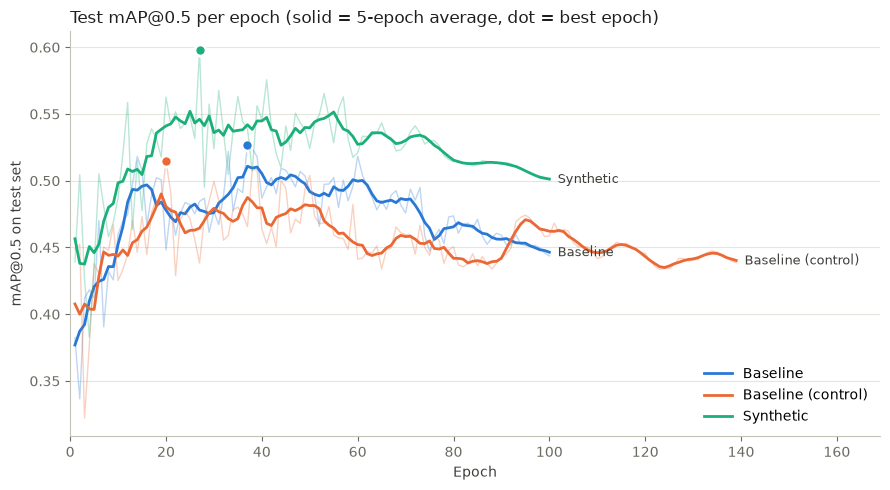

,run,epochs_planned,epochs_trained,best_epoch,best_mAP50,mean_last_10_epochs,final_mAP50
0,Baseline,100,100,37,0.527,0.451,0.444
1,Baseline (control),157,139,20,0.515,0.443,0.439
2,Synthetic,100,100,27,0.598,0.507,0.501


In [ ]:
# ============================================================
# Step 15: Does more training help? (score after every epoch)
# ============================================================
import yaml
import pandas as pd
import matplotlib.pyplot as plt

runs = {
    "Baseline":           ("baseline_yolov8l",       "#2a78d6"),
    "Baseline (control)": ("baseline_157ep_yolov8l", "#eb6834"),
    "Synthetic":          ("synthetic_yolov8l",      "#1baf7a"),
}

fig, ax = plt.subplots(figsize=(9, 5))
rows = []
for label, (folder, color) in runs.items():
    df = pd.read_csv(RUNS_DIR / folder / "results.csv")
    df.columns = df.columns.str.strip()
    planned = yaml.safe_load(open(RUNS_DIR / folder / "args.yaml"))["epochs"]

    epoch = df["epoch"]
    score = df["metrics/mAP50(B)"]
    smooth = score.rolling(5, center=True, min_periods=1).mean()
    best = score.idxmax()

    ax.plot(epoch, score, color=color, linewidth=1, alpha=0.3)              # raw
    ax.plot(epoch, smooth, color=color, linewidth=2, label=label)           # trend
    ax.plot(epoch[best], score[best], "o", color=color, markersize=8,
            markeredgecolor="white", markeredgewidth=2)                     # best epoch
    ax.annotate(label, (epoch.iloc[-1], smooth.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#3d3d3a")

    rows.append({"run": label,
                 "epochs_planned": planned,
                 "epochs_trained": len(df),
                 "best_epoch": int(epoch[best]),
                 "best_mAP50": round(score[best], 3),
                 "mean_last_10_epochs": round(score.iloc[-10:].mean(), 3),
                 "final_mAP50": round(score.iloc[-1], 3)})

ax.set_xlabel("Epoch", color="#3d3d3a")
ax.set_ylabel("mAP@0.5 on test set", color="#3d3d3a")
ax.set_title("Test mAP@0.5 per epoch (solid = 5-epoch average, dot = best epoch)",
             color="#1f1f1e", loc="left")
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#6b6a63")
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(0, max(r["epochs_trained"] for r in rows) + 30)
plt.tight_layout()
Path("results").mkdir(exist_ok=True)
plt.savefig("results/training_curves.png", dpi=200)
plt.show()

curves = pd.DataFrame(rows)
curves.to_csv("results/training_curves_summary.csv", index=False)
curves

## Step 16: Create a real validation set (split the training set by camera)

Until now, the test set was also used as the validation set (like the paper), so `best.pt` was the epoch with the highest **test** score. The training curves (Step 15) showed this makes the results a little optimistic.

Here about 15% of the training images become a **validation set**. Whole cameras are held out, the same idea as the paper's train/test split, so validation also uses cameras the model has not seen. No images are copied; the split is saved as two lists of image paths in `data/fisheye8k/splits/`.

In [ ]:
# ============================================================
# Step 16: Create a real validation set (split the training set by camera)
# ============================================================
import re
import itertools

VAL_FRACTION = 0.15
SPLIT_DIR = DATA_DIR / "splits"


def camera_of(image_path):
    """Camera name from the file name, e.g. camera3_A_12.png -> camera3."""
    match = re.match(r"(camera\d+)", image_path.stem, re.IGNORECASE)
    return match.group(1).lower() if match else image_path.stem.split("_")[0]


def create_validation_split():
    import pandas as pd

    images = sorted((DATA_DIR / "train" / "images").glob("*"))
    cameras = {}
    for p in images:
        cameras.setdefault(camera_of(p), []).append(p)
    if len(cameras) > 30:
        raise ValueError(f"Could not find camera names. Example file names: {[p.name for p in images[:5]]}")

    # Choose the group of cameras whose image count is closest to 15%
    target = VAL_FRACTION * len(images)
    names = sorted(cameras)
    best = None
    for k in range(1, len(names)):
        for combo in itertools.combinations(names, k):
            n = sum(len(cameras[c]) for c in combo)
            if best is None or abs(n - target) < abs(best[1] - target):
                best = (combo, n)
    val_cameras = set(best[0])

    # Save the two lists
    SPLIT_DIR.mkdir(parents=True, exist_ok=True)
    train_list = [p for c in names if c not in val_cameras for p in cameras[c]]
    val_list = [p for c in sorted(val_cameras) for p in cameras[c]]
    (SPLIT_DIR / "train.txt").write_text("\n".join(p.resolve().as_posix() for p in train_list))
    (SPLIT_DIR / "val.txt").write_text("\n".join(p.resolve().as_posix() for p in val_list))

    # Report: images and boxes per class in each part
    def class_counts(paths):
        counts = Counter()
        for p in paths:
            label = DATA_DIR / "train" / "labels" / (p.stem + ".txt")
            for line in label.read_text().splitlines():
                if line.strip():
                    counts[CLASS_NAMES[int(line.split()[0])]] += 1
        return counts

    print("Cameras in the training set:", {c: len(cameras[c]) for c in names})
    print("Validation cameras:", sorted(val_cameras))
    table = pd.DataFrame([{"part": "train", "images": len(train_list), **class_counts(train_list)},
                          {"part": "val", "images": len(val_list), **class_counts(val_list)}])
    table = table[["part", "images"] + CLASS_NAMES]          # classes in the usual order
    table.to_csv(SPLIT_DIR / "split_summary.csv", index=False)
    print(table.to_string(index=False))
    print(f"Validation = {100 * len(val_list) / len(images):.1f}% of the training images")


create_validation_split()

Cameras in the training set: {'camera10': 500, 'camera11': 421, 'camera12': 30, 'camera13': 780, 'camera14': 498, 'camera15': 73, 'camera16': 50, 'camera17': 86, 'camera18': 33, 'camera3': 1617, 'camera5': 179, 'camera6': 43, 'camera8': 536, 'camera9': 442}
Validation cameras: ['camera12', 'camera14', 'camera17', 'camera5']
 part  images  Bus  Bike   Car  Pedestrian  Truck
train    4495 1731 54145 30288        7975   1652
  val     793  323  8116  6348        1151    484
Validation = 15.0% of the training images


## Step 17: Retrain baseline and synthetic with the validation set

Same settings as before (YOLOv8l, 640, batch 8, seed 0, COCO weights). Only two changes:
1. Validation uses the held-out cameras, not the test set.
2. Early stopping: training stops if the validation score does not improve for 20 epochs (Step 15 showed all models peak around epoch 20–37).

*Both trainings together take about 7–9 hours. Already-trained models are skipped.*

In [ ]:
# ============================================================
# Step 17: Retrain baseline and synthetic with the validation set
# ============================================================
VAL_YAML = DATA_DIR / "fisheye8k_valsplit.yaml"
VAL_SYNTH_YAML = DATA_DIR / "fisheye8k_valsplit_synthetic.yaml"


def write_split_yaml(path, train_sources):
    text = "train:\n"
    for source in train_sources:
        text += f"  - {Path(source).resolve().as_posix()}\n"
    text += f"val: {(SPLIT_DIR / 'val.txt').resolve().as_posix()}\nnames:\n"
    for i, name in enumerate(CLASS_NAMES):
        text += f"  {i}: {name}\n"
    path.write_text(text)


def train_with_validation(name, data_yaml):
    from ultralytics import YOLO

    best = RUNS_DIR / name / "weights" / "best.pt"
    if best.exists():
        print("Already trained:", best)
        return
    last = RUNS_DIR / name / "weights" / "last.pt"
    if last.exists():
        print("Resuming from:", last)
        YOLO(last).train(resume=True)
        return

    YOLO("yolov8l.pt").train(
        data=str(data_yaml),
        imgsz=640,
        epochs=100,
        patience=20,                # early stopping on the validation set
        batch=8,
        workers=4,
        device=0,
        project=str(RUNS_DIR),
        name=name,
        seed=0,
    )


def train_both_with_validation():
    write_split_yaml(VAL_YAML, [SPLIT_DIR / "train.txt"])
    write_split_yaml(VAL_SYNTH_YAML, [SPLIT_DIR / "train.txt", SYNTH_DIR / "images"])
    train_with_validation("valsplit_baseline", VAL_YAML)
    train_with_validation("valsplit_synthetic", VAL_SYNTH_YAML)


train_both_with_validation()

New https://pypi.org/project/ultralytics/8.4.203 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\fisheye8k\fisheye8k_valsplit.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

## Step 18: Final test – each model is tested once on the test set

The two models from Step 17 chose their best epoch using the **validation** cameras only. Now each model is tested **one time** on the FishEye8K test set. This gives a fair result that was not tuned on the test set.

For each model the table shows: how many epochs it trained (early stopping), which epoch was chosen, the official test mAP, and the ring results.

In [ ]:
# ============================================================
# Step 18: Final test - each model is tested ONCE on the test set
# ============================================================
def final_test():
    import pandas as pd
    from ultralytics import YOLO

    models = {"Baseline (val split)": "valsplit_baseline",
              "Synthetic (val split)": "valsplit_synthetic"}
    rows = []
    for label, name in models.items():
        weights = RUNS_DIR / name / "weights" / "best.pt"

        # Which epoch was chosen (by the validation set)
        log = pd.read_csv(RUNS_DIR / name / "results.csv")
        log.columns = log.columns.str.strip()
        fitness = 0.1 * log["metrics/mAP50(B)"] + 0.9 * log["metrics/mAP50-95(B)"]  # Ultralytics rule

        # One test: official Ultralytics result (DATA_YAML: val = test set)
        m = YOLO(weights).val(data=str(DATA_YAML), imgsz=640, batch=8, device=0,
                              plots=False, verbose=False)
        # Ring results on the test set
        radius_evaluation(weights, name=name)
        t = pd.read_csv(f"results/{name}_radius_eval.csv")
        t = t[t["class"] == "all"].set_index("ring")

        rows.append({"model": label,
                     "epochs_trained": len(log),
                     "best_epoch": int(log["epoch"][fitness.idxmax()]),
                     "test_mAP50": m.box.map50, "test_mAP50_95": m.box.map,
                     "center": t.loc["center", "mAP50"], "middle": t.loc["middle", "mAP50"],
                     "edge": t.loc["edge", "mAP50"],
                     "edge_gap": t.loc["center", "mAP50"] - t.loc["edge", "mAP50"]})

    table = pd.DataFrame(rows).round(3)
    table.to_csv("results/final_test_valsplit.csv", index=False)
    return table


final_test()

Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 112 layers, 43,610,463 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 520.0±107.4 MB/s, size: 1323.6 KB)
val: Scanning C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\test\labels.cache... 2712 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2712/2712  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 339/339 4.0it/s 1:240.2sss
                   all       2712      45145      0.672      0.429      0.494      0.281
Speed: 2.4ms preprocess, 19.3ms inference, 0.0ms loss, 1.4ms postprocess per image
  predicted 500 images
  predicted 1000 images
  predicted 1500 images
  predicted 2000 images
  predicted 2500 images
Saved predictions: results/valsplit_baseline_predictions.csv

=== Radius-stratified evaluation: valsplit_baseline ===
  ring class  n_gt  mAP

,model,epochs_trained,best_epoch,test_mAP50,test_mAP50_95,center,middle,edge,edge_gap
0,Baseline (val split),53,33,0.494,0.281,0.843,0.622,0.442,0.400
1,Synthetic (val split),83,53,0.517,0.311,0.936,0.658,0.474,0.461


## Step 19: Fair synthetic model at higher input resolutions

Step 14 showed that testing at a bigger input size (800–960) helped the small edge objects. Here I repeat that test with the **fair** synthetic model from Step 17 (epoch chosen by the validation set, not the test set).

*No training. About 15–20 minutes.*

In [ ]:
# ============================================================
# Step 19: Fair synthetic model at higher input resolutions
# ============================================================
test_resolutions(weights=RUNS_DIR / "valsplit_synthetic" / "weights" / "best.pt",
                 name="valsplit_synthetic", sizes=(640, 800, 960))


===== Input size 640 =====
Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 112 layers, 43,610,463 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 971.3±520.5 MB/s, size: 1420.7 KB)
val: Scanning C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\test\labels.cache... 2712 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2712/2712  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 678/678 6.9it/s 1:380.1ssss
                   all       2712      45145      0.651      0.459      0.517      0.311
Speed: 3.0ms preprocess, 20.3ms inference, 0.0ms loss, 2.4ms postprocess per image
Saved predictions: results/valsplit_synthetic_640_predictions.csv
Loading saved predictions: results/valsplit_synthetic_640_predictions.csv

=== Radius-stratified evaluation: valsplit_synthetic_640 ===
  ring class  n_gt  mAP50  mA

,input_size,mAP50,mAP50_95,center,middle,edge,ms_per_image,FPS
0,640,0.517,0.311,0.936,0.658,0.474,25.664,38.964
1,800,0.539,0.323,0.888,0.646,0.513,34.859,28.687
2,960,0.534,0.317,0.868,0.627,0.498,47.415,21.090


In [ ]:
# Choose the input size on the VALIDATION cameras (not the test set)
from ultralytics import YOLO
model = YOLO(RUNS_DIR / "valsplit_synthetic" / "weights" / "best.pt")
for size in (640, 800, 960):
    m = model.val(data=str(VAL_SYNTH_YAML), imgsz=size, batch=4, device=0,
                  plots=False, verbose=False)
    print(f"size {size}: validation mAP50 = {m.box.map50:.3f}, mAP50-95 = {m.box.map:.3f}")

Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
Model summary (fused): 112 layers, 43,610,463 parameters, 0 gradients, 164.8 GFLOPs
val: Fast image access  (ping: 0.2±0.1 ms, read: 586.2±101.7 MB/s, size: 2258.9 KB)
val: Scanning C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\train\labels.cache... 793 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 793/793  0.0s
val: C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\train\images\camera17_A_52.png: 1 duplicate labels removed
val: C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\train\images\camera17_A_57.png: 1 duplicate labels removed
val: C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\train\images\camera17_A_67.png: 1 duplicate labels removed
val: C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\train\images\camera17_A_70.png: 1 duplicate labels removed
val: C:\Users\itsfr\Desktop\Master\fisheye-project\data\fisheye8k\tra

## Step 20: Pick a small sample for hand labelling

To test rotated and polygon boxes, I need the real shape of some objects. Here I pick **30 test images** with many edge objects (at most 3 per camera, so one camera does not fill the sample) and copy them to `data/label_sample/`. I will draw a polygon around each object in **labelme**.

In [ ]:
# ============================================================
# Step 20: Pick a small sample of test images for hand labelling
# ============================================================
import shutil

LABEL_DIR = Path("data/label_sample")


def pick_label_sample(n_images=30, seed=0):
    import pandas as pd

    gt = load_ground_truth()
    gt["ring"] = ring_of((gt.x1 + gt.x2) / 2, (gt.y1 + gt.y2) / 2)
    per_image = gt.groupby("image").agg(n=("cls", "size"),
                                        n_edge=("ring", lambda r: (r == "edge").sum()))
    # one camera should not fill the sample: at most 3 images per camera
    per_image["camera"] = [camera_of(Path(i)) for i in per_image.index]
    per_image = per_image[(per_image.n_edge >= 5) & (per_image.n <= 40)]   # busy, but possible to label
    sample = (per_image.sample(frac=1, random_state=seed)
              .groupby("camera").head(3).head(n_images))

    LABEL_DIR.mkdir(parents=True, exist_ok=True)
    for image in sample.index:
        src = next((DATA_DIR / "test" / "images").glob(image + ".*"))
        shutil.copy2(src, LABEL_DIR / src.name)
    sample.to_csv(LABEL_DIR / "sample_list.csv")
    print(f"Copied {len(sample)} images from {sample.camera.nunique()} cameras to {LABEL_DIR.resolve()}")
    print(f"Objects in these images: {int(sample.n.sum())} (edge: {int(sample.n_edge.sum())})")


pick_label_sample()

Copied 12 images from 4 cameras to C:\Users\itsfr\Desktop\Master\fisheye-project\data\label_sample
Objects in these images: 249 (edge: 215)


## Step 21: Automatic rotated boxes (radial pseudo-OBB) and OBB training

In a fisheye image, objects lean along the **radial direction** (the line from the image center to the object). From each normal box (W × H) and that angle t, geometry gives the tightest rotated rectangle that fits inside the box and touches all four sides:

w = (W cos t − H sin t) / (cos²t − sin²t),  h = (H cos t − W sin t) / (cos²t − sin²t)

If no such rectangle exists (for example a square box at 45°), or it would be a thin sliver, the normal box is kept. So rotated labels are made **automatically, with no hand labelling**.

Then I train **YOLOv8l-OBB** (the rotated-box version of YOLOv8) on these labels, with the same settings and the same validation split as the fair models (Step 17).

*Creating the labels takes a few minutes. Training takes several hours (early stopping).*

In [ ]:
# ============================================================
# Step 21: Automatic rotated boxes (radial pseudo-OBB) + OBB training
# ============================================================
OBB_DIR = Path("data/fisheye8k_obb")
OBB_YAML = OBB_DIR / "fisheye8k_obb.yaml"


def radial_obb(cx, cy, W, H, min_side=0.002):
    """Normalized box (center, size) -> 4 corners of the radial rotated box,
    and True if it was rotated (False = normal box kept)."""
    phi = np.arctan2(cy - 0.5, cx - 0.5)               # radial angle
    t = phi % (np.pi / 2)                                # a rectangle repeats every 90 degrees
    if t > np.pi / 4:
        t -= np.pi / 2                                   # use the angle in (-45, 45] degrees
    c, s = np.cos(t), abs(np.sin(t))
    det = c * c - s * s
    rotated = False
    if det > 0.05:
        w = (W * c - H * s) / det
        h = (H * c - W * s) / det
        # only rotate if the rotated box keeps a reasonable thickness
        # (no thin slivers: a real car or person is never a line)
        if min(w, h) > min_side and min(w, h) >= 0.35 * min(W, H):
            rotated = True
    if not rotated:
        t, w, h = 0.0, W, H
    u = np.array([np.cos(t), np.sin(t)])                 # along w
    v = np.array([-np.sin(t), np.cos(t)])                # along h
    center = np.array([cx, cy])
    corners = [center + a * w / 2 * u + b * h / 2 * v
               for a, b in [(-1, -1), (1, -1), (1, 1), (-1, 1)]]
    return np.clip(np.array(corners), 0, 1), rotated


def create_obb_dataset():
    """Same images (hard links, no extra space), labels in OBB format:
    class x1 y1 x2 y2 x3 y3 x4 y4 (normalized)."""
    import os

    n_boxes = n_rotated = 0
    for split in ["train", "test"]:
        (OBB_DIR / split / "images").mkdir(parents=True, exist_ok=True)
        (OBB_DIR / split / "labels").mkdir(parents=True, exist_ok=True)
        for src in (DATA_DIR / split / "images").glob("*"):
            dst = OBB_DIR / split / "images" / src.name
            if not dst.exists():
                try:
                    os.link(src, dst)                    # hard link: no extra disk space
                except OSError:
                    shutil.copy2(src, dst)
        for label in (DATA_DIR / split / "labels").glob("*.txt"):
            lines = []
            for line in label.read_text().splitlines():
                if not line.strip():
                    continue
                c, x, y, w, h = map(float, line.split())
                corners, rotated = radial_obb(x, y, w, h)
                lines.append(f"{int(c)} " + " ".join(f"{p:.6f}" for p in corners.ravel()))
                n_boxes += 1
                n_rotated += rotated
            (OBB_DIR / split / "labels" / label.name).write_text("\n".join(lines))

    # Same train/val split as Step 16, pointing to the OBB folder
    for part in ["train", "val"]:
        paths = (SPLIT_DIR / f"{part}.txt").read_text().split("\n")
        new = [p.replace("/fisheye8k/train/images/", "/fisheye8k_obb/train/images/") for p in paths]
        (OBB_DIR / f"{part}.txt").write_text("\n".join(new))

    text = (f"train: {(OBB_DIR / 'train.txt').resolve().as_posix()}\n"
            f"val: {(OBB_DIR / 'val.txt').resolve().as_posix()}\n"
            f"test: {(OBB_DIR / 'test' / 'images').resolve().as_posix()}\nnames:\n")
    for i, name in enumerate(CLASS_NAMES):
        text += f"  {i}: {name}\n"
    OBB_YAML.write_text(text)
    print(f"OBB labels: {n_boxes} boxes, {n_rotated} rotated ({100 * n_rotated / n_boxes:.1f}%), "
          f"{n_boxes - n_rotated} kept as normal boxes")


def preview_obb(n=4):
    """Draw normal boxes (thin gray) and radial rotated boxes (colour) on a few
    training images, to check the rotated boxes before training."""
    import cv2

    colors = [(0, 165, 255), (255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 0, 255)]
    labels = sorted((OBB_DIR / "train" / "labels").glob("*.txt"))
    rng = np.random.default_rng(1)
    tiles = []
    for label in rng.choice(labels, size=n, replace=False):
        image_path = next((OBB_DIR / "train" / "images").glob(label.stem + ".*"))
        image = cv2.imread(str(image_path))
        H_img, W_img = image.shape[:2]
        normal = (DATA_DIR / "train" / "labels" / label.name).read_text().splitlines()
        for line in normal:
            if line.strip():
                _, x, y, w, h = map(float, line.split())
                cv2.rectangle(image, (int((x - w / 2) * W_img), int((y - h / 2) * H_img)),
                              (int((x + w / 2) * W_img), int((y + h / 2) * H_img)), (200, 200, 200), 1)
        for line in label.read_text().splitlines():
            if line.strip():
                v = list(map(float, line.split()))
                pts = (np.array(v[1:]).reshape(4, 2) * [W_img, H_img]).astype(np.int32)
                cv2.polylines(image, [pts], True, colors[int(v[0])], 2)
        tiles.append(cv2.resize(image, (720, 720)))
    grid = np.vstack([np.hstack(tiles[:2]), np.hstack(tiles[2:4])])
    Path("results").mkdir(exist_ok=True)
    cv2.imwrite("results/pseudo_obb_preview.jpg", grid)
    print("Saved: results/pseudo_obb_preview.jpg (gray = normal box, colour = rotated box)")


def train_obb():
    """YOLOv8l-OBB, same settings as the fair models (Step 17)."""
    from ultralytics import YOLO

    name = "valsplit_obb"
    best = RUNS_DIR / name / "weights" / "best.pt"
    if best.exists():
        print("Already trained:", best)
        return
    last = RUNS_DIR / name / "weights" / "last.pt"
    if last.exists():
        print("Resuming from:", last)
        YOLO(last).train(resume=True)
        return
    YOLO("yolov8l-obb.pt").train(
        data=str(OBB_YAML), imgsz=640, epochs=100, patience=20, batch=8,
        workers=4, device=0, project=str(RUNS_DIR), name=name, seed=0)


#create_obb_dataset()
#preview_obb()

In [ ]:
train_obb()

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.201  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data\fisheye8k_obb\fisheye8k_obb.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=

## Step 24: Does the OBB model still detect as well? (normal mAP on the test set)

The rotated-box model (Step 21) is trained on automatic rotated labels. To compare it fairly with the normal model, its rotated predictions are turned into straight boxes (the box around the 4 corners) and evaluated exactly like the other models: mAP and rings on the test set, used once.

*No training. About 5 minutes.*

In [ ]:
# ============================================================
# Step 24: Does the OBB model still detect as well? (normal mAP on the test set)
# ============================================================
def obb_test_as_boxes(name="valsplit_obb"):
    import pandas as pd
    from ultralytics import YOLO

    # saved with the name radius_evaluation looks for: results/<name>_box_predictions.csv
    cache = Path(f"results/{name}_box_predictions.csv")
    if not cache.exists():
        model = YOLO(RUNS_DIR / name / "weights" / "best.pt")
        rows = []
        for result in model.predict(source=str(DATA_DIR / "test" / "images"), imgsz=640,
                                    conf=0.001, iou=0.7, max_det=300, device=0,
                                    stream=True, verbose=False):
            image = Path(result.path).stem
            corners = result.obb.xyxyxyxyn.cpu().numpy()
            for pts, c, s in zip(corners, result.obb.cls.cpu().numpy(), result.obb.conf.cpu().numpy()):
                pts = np.clip(pts, 0, 1)
                rows.append((image, int(c), float(s), pts[:, 0].min(), pts[:, 1].min(),
                             pts[:, 0].max(), pts[:, 1].max()))
        pd.DataFrame(rows, columns=["image", "cls", "conf", "x1", "y1", "x2", "y2"]).to_csv(cache, index=False)
        print("Saved:", cache)
    radius_evaluation(RUNS_DIR / name / "weights" / "best.pt", name=f"{name}_box")


obb_test_as_boxes()

Saved: results\valsplit_obb_box_predictions.csv
Loading saved predictions: results/valsplit_obb_box_predictions.csv

=== Radius-stratified evaluation: valsplit_obb_box ===
  ring class  n_gt  mAP50  mAP50_95  mean_box_area_%
   all   all 45145 0.4186    0.2190           0.2655
center   all   426 0.6772    0.4267           1.3181
middle   all  9203 0.5194    0.3086           0.5435
  edge   all 35516 0.3925    0.1953           0.1808

Edge gap (mAP50):     0.2847
Edge gap (mAP50-95):  0.2314

Per-class results saved in: results/valsplit_obb_box_radius_eval.csv


## Step 22: Shape fit on the hand-labelled sample

For every hand-drawn polygon (the real object shape), I compare three boxes:
- **normal**: the straight box around the polygon (what FishEye8K uses)
- **rotated**: the smallest rotated box around the polygon (the best a rotated box can do)
- **radial**: the automatic radial rotated box from Step 21, made only from the normal box and the angle to the image center

Measures: **IoU** with the real shape, and **fill** = how much of the box is really the object (the rest is background). Results are given by ring and by class.

In [ ]:
# ============================================================
# Step 22: Shape fit on the hand-labelled sample
# ============================================================
import json


def load_hand_polygons():
    """Read the labelme .json files. Returns a list of dicts in pixels."""
    rows = []
    for file in sorted(LABEL_DIR.glob("*.json")):
        data = json.loads(file.read_text(encoding="utf-8"))
        W, H = data["imageWidth"], data["imageHeight"]
        for shape in data["shapes"]:
            name = shape["label"].strip().capitalize()
            if name not in CLASS_NAMES or len(shape["points"]) < 3:
                print(f"  skipped a shape in {file.name}: label '{shape['label']}'")
                continue
            poly = np.array(shape["points"], dtype=np.float64)
            rows.append({"image": file.stem, "cls": CLASS_NAMES.index(name),
                         "poly": poly, "W": W, "H": H})
    return rows


def poly_iou(a, b, scale=4):
    """IoU of two polygons (pixels), by drawing both as masks."""
    import cv2
    pts = np.vstack([a, b])
    x0, y0 = np.floor(pts.min(0)) - 2
    x1, y1 = np.ceil(pts.max(0)) + 2
    size = (int((y1 - y0) * scale) + 1, int((x1 - x0) * scale) + 1)
    ma, mb = np.zeros(size, np.uint8), np.zeros(size, np.uint8)
    cv2.fillPoly(ma, [np.round((a - [x0, y0]) * scale).astype(np.int32)], 1)
    cv2.fillPoly(mb, [np.round((b - [x0, y0]) * scale).astype(np.int32)], 1)
    union = np.logical_or(ma, mb).sum()
    return np.logical_and(ma, mb).sum() / union if union else 0.0


def poly_area(p):
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))


def box_corners(x1, y1, x2, y2):
    return np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype=np.float64)


def shape_fit():
    import cv2
    import pandas as pd

    rows = []
    for obj in load_hand_polygons():
        poly, W, H = obj["poly"], obj["W"], obj["H"]
        x1, y1 = poly.min(0)
        x2, y2 = poly.max(0)
        normal = box_corners(x1, y1, x2, y2)
        rotated = cv2.boxPoints(cv2.minAreaRect(poly.astype(np.float32))).astype(np.float64)
        cx, cy = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H
        radial_n, was_rotated = radial_obb(cx, cy, (x2 - x1) / W, (y2 - y1) / H)
        radial = radial_n * [W, H]
        area = poly_area(poly)
        rows.append({"image": obj["image"], "class": CLASS_NAMES[obj["cls"]],
                     "ring": ring_of(np.array([cx]), np.array([cy]))[0],
                     "iou_normal": poly_iou(poly, normal),
                     "iou_rotated": poly_iou(poly, rotated),
                     "iou_radial": poly_iou(poly, radial),
                     "radial_was_rotated": was_rotated,
                     "fill_normal": area / poly_area(normal),
                     "fill_rotated": area / poly_area(rotated)})
    df = pd.DataFrame(rows)
    df.to_csv("results/shape_fit_objects.csv", index=False)

    cols = ["iou_normal", "iou_rotated", "iou_radial", "fill_normal", "fill_rotated"]
    by_ring = df.groupby("ring")[cols].mean().reindex(list(RINGS))
    by_ring.insert(0, "objects", df.groupby("ring").size().reindex(list(RINGS)))
    by_ring.loc["all"] = [len(df)] + list(df[cols].mean())
    by_class = df.groupby("class")[cols].mean()
    by_class.insert(0, "objects", df.groupby("class").size())
    by_ring.round(3).to_csv("results/shape_fit_by_ring.csv")
    by_class.round(3).to_csv("results/shape_fit_by_class.csv")
    print(f"Hand-labelled objects: {len(df)} in {df.image.nunique()} images "
          f"(radial box rotated for {100 * df.radial_was_rotated.mean():.0f}%)")
    print("\n=== Shape fit by ring (mean IoU with the real shape; fill = object share of the box) ===")
    print(by_ring.round(3).to_string())
    print("\n=== Shape fit by class ===")
    print(by_class.round(3).to_string())


shape_fit()

Hand-labelled objects: 43 in 12 images (radial box rotated for 77%)

=== Shape fit by ring (mean IoU with the real shape; fill = object share of the box) ===
        objects  iou_normal  iou_rotated  iou_radial  fill_normal  fill_rotated
ring                                                                           
center      NaN         NaN          NaN         NaN          NaN           NaN
middle      7.0       0.587        0.876       0.691        0.585         0.875
edge       36.0       0.651        0.830       0.669        0.649         0.830
all        43.0       0.640        0.838       0.673        0.639         0.838

=== Shape fit by class ===
            objects  iou_normal  iou_rotated  iou_radial  fill_normal  fill_rotated
class                                                                              
Bike             13       0.677        0.838       0.692        0.675         0.838
Bus               4       0.561        0.793       0.610        0.560         0.79

## Step 23: Do rotated-box predictions fit the real shapes better?

Both models were trained on the same images and the same split (Step 16): `valsplit_baseline` with normal boxes and `valsplit_obb` with automatic rotated boxes. For every hand-drawn polygon, I take the best-overlapping prediction of the same class (confidence ≥ 0.25) and measure its IoU with the real shape.

In [ ]:
# ============================================================
# Step 23: Do OBB predictions fit the real shapes better?
# ============================================================
def predict_label_sample(weights, name, obb):
    import pandas as pd

    cache = Path(f"results/{name}_sample_predictions.csv")
    if cache.exists():
        return pd.read_csv(cache)
    from ultralytics import YOLO
    model = YOLO(weights)
    rows = []
    images = [p for p in sorted(LABEL_DIR.glob("*")) if p.suffix.lower() in (".png", ".jpg", ".jpeg")]
    for result in model.predict([str(p) for p in images], imgsz=640, conf=0.25,
                                device=0, verbose=False, stream=True):
        image = Path(result.path).stem
        if obb:
            corners = result.obb.xyxyxyxy.cpu().numpy()
            cls, conf = result.obb.cls.cpu().numpy(), result.obb.conf.cpu().numpy()
        else:
            corners = np.array([box_corners(*b) for b in result.boxes.xyxy.cpu().numpy()])
            cls, conf = result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy()
        for pts, c, s in zip(corners, cls, conf):
            rows.append([image, int(c), float(s)] + list(np.asarray(pts).ravel()))
    cols = ["image", "cls", "conf"] + [f"p{i}" for i in range(8)]
    df = pd.DataFrame(rows, columns=cols)
    df.to_csv(cache, index=False)
    return df


def prediction_fit():
    import pandas as pd

    models = {"Normal boxes (valsplit_baseline)": ("valsplit_baseline", False),
              "Rotated boxes (valsplit_obb)": ("valsplit_obb", True)}
    hand = load_hand_polygons()
    rows = []
    for label, (name, obb) in models.items():
        preds = predict_label_sample(RUNS_DIR / name / "weights" / "best.pt", name, obb)
        for obj in hand:
            p = preds[(preds.image == obj["image"]) & (preds.cls == obj["cls"])]
            best = max((poly_iou(obj["poly"], r[[f"p{i}" for i in range(8)]].to_numpy(float).reshape(4, 2))
                        for _, r in p.iterrows()), default=0.0)
            x1, y1 = obj["poly"].min(0)
            x2, y2 = obj["poly"].max(0)
            ring = ring_of(np.array([(x1 + x2) / 2 / obj["W"]]), np.array([(y1 + y2) / 2 / obj["H"]]))[0]
            rows.append({"model": label, "class": CLASS_NAMES[obj["cls"]], "ring": ring, "best_iou": best})
    df = pd.DataFrame(rows)
    df.to_csv("results/prediction_fit_objects.csv", index=False)

    def summary(group):
        g = df.groupby(["model", group]).best_iou
        return pd.DataFrame({"mean_iou": g.mean(), "found_iou>=0.5_%": 100 * g.apply(lambda s: (s >= 0.5).mean())}).round(3)
    overall = df.groupby("model").best_iou.agg(mean_iou="mean", **{"found_iou>=0.5_%": lambda s: 100 * (s >= 0.5).mean()}).round(3)
    print("=== Prediction fit with the real shapes (all hand-labelled objects) ===")
    print(overall.to_string())
    print("\n=== By ring ===")
    print(summary("ring").unstack(0).to_string())
    print("\n=== By class ===")
    print(summary("class").unstack(0).to_string())
    overall.to_csv("results/prediction_fit_overall.csv")
    summary("ring").to_csv("results/prediction_fit_by_ring.csv")
    summary("class").to_csv("results/prediction_fit_by_class.csv")


prediction_fit() 

=== Prediction fit with the real shapes (all hand-labelled objects) ===
                                  mean_iou  found_iou>=0.5_%
model                                                       
Normal boxes (valsplit_baseline)     0.401            51.163
Rotated boxes (valsplit_obb)         0.378            48.837

=== By ring ===
                               mean_iou                                              found_iou>=0.5_%                             
model  Normal boxes (valsplit_baseline) Rotated boxes (valsplit_obb) Normal boxes (valsplit_baseline) Rotated boxes (valsplit_obb)
ring                                                                                                                              
edge                              0.409                        0.388                           50.000                       50.000
middle                            0.359                        0.325                           57.143                       42.857

=== By clas

## Step 25: Pedestrian vs Bike confusion (per ring)

In FishEye8K, a scooter with its rider is **one "Bike" box**, and a walking person is **"Pedestrian"**. Seen from above in a fisheye image, a rider can look like a pedestrian, and the reverse. Pedestrian is also the weakest class.

For every real object, I check the predictions (confidence ≥ 0.25) that overlap it with IoU ≥ 0.5:
- **correct:** one of them has the right class
- **as X:** it was found, but only with the wrong class X
- **missed:** no prediction overlaps it

*No training: uses the saved test predictions of the two fair models. About 1 minute.*

In [ ]:
# ============================================================
# Step 25: Pedestrian vs Bike confusion (per ring)
# ============================================================
def class_confusion(names=("valsplit_baseline", "valsplit_synthetic"), conf=0.25):
    import pandas as pd

    gt = load_ground_truth()
    gt["ring"] = ring_of((gt.x1 + gt.x2) / 2, (gt.y1 + gt.y2) / 2)
    tables = []
    for name in names:
        preds = pd.read_csv(f"results/{name}_predictions.csv")
        preds = preds[preds.conf >= conf]
        p_groups = dict(tuple(preds.groupby("image")))
        outcome = []
        for image, g in gt.groupby("image"):
            p = p_groups.get(image)
            if p is None:
                outcome += [(i, "missed") for i in g.index]
                continue
            iou = box_iou(g[["x1", "y1", "x2", "y2"]].to_numpy(), p[["x1", "y1", "x2", "y2"]].to_numpy())
            p_cls = p.cls.to_numpy()
            for k, (i, true_cls) in enumerate(zip(g.index, g.cls)):
                hit = iou[k] >= 0.5
                if not hit.any():
                    outcome.append((i, "missed"))
                elif (p_cls[hit] == true_cls).any():
                    outcome.append((i, "correct"))
                else:
                    best = np.argmax(np.where(hit, iou[k], -1))
                    outcome.append((i, "as " + CLASS_NAMES[p_cls[best]]))
        o = pd.Series(dict(outcome))
        df = gt.assign(outcome=o.reindex(gt.index).values, true=[CLASS_NAMES[c] for c in gt.cls])

        for ring in ["all"] + list(RINGS):
            d = df if ring == "all" else df[df.ring == ring]
            share = pd.crosstab(d.true, d.outcome, normalize="index") * 100
            share.insert(0, "objects", d.groupby("true").size())
            share = share.reset_index().assign(model=name, ring=ring)
            tables.append(share)

    table = pd.concat(tables, ignore_index=True).fillna(0)
    order = ["model", "ring", "true", "objects", "correct", "missed"] + \
            [c for c in table.columns if str(c).startswith("as ")]
    table = table[[c for c in order if c in table.columns]].round(1)
    table.to_csv("results/class_confusion.csv", index=False)

    show = table[table.true.isin(["Pedestrian", "Bike"])]
    for name in names:
        print(f"\n=== {name}: what happened to real Pedestrians and Bikes (% of objects) ===")
        print(show[show.model == name].drop(columns="model").to_string(index=False))
    print("\nSaved (all classes): results/class_confusion.csv")


class_confusion()


=== valsplit_baseline: what happened to real Pedestrians and Bikes (% of objects) ===
  ring       true  objects  correct  missed  as Bike  as Bus  as Car  as Pedestrian  as Truck
   all       Bike    26270     43.6    54.1      0.0     0.0     1.1            1.2       0.0
   all Pedestrian     2633     21.4    65.4     12.8     0.0     0.3            0.0       0.0
center       Bike      331     99.4     0.3      0.0     0.0     0.0            0.3       0.0
center Pedestrian       17     70.6    11.8     17.6     0.0     0.0            0.0       0.0
middle       Bike     4884     75.4    23.3      0.0     0.0     0.2            1.0       0.0
middle Pedestrian      494     26.3    57.9     15.6     0.0     0.0            0.0       0.2
  edge       Bike    21055     35.3    62.1      0.0     0.0     1.3            1.2       0.0
  edge Pedestrian     2122     19.9    67.6     12.1     0.0     0.4            0.0       0.0

=== valsplit_synthetic: what happened to real Pedestrians and Bike

In [ ]:
# ============================================================
# Report figures: check which images exist, remake the missing ones
# ============================================================
import shutil

figures = {
    "synthetic_examples.jpg":         "Step 8 (preview_synthetic)",
    "training_curves.png":            "Step 15 (training curves cell)",
    "rectified_views_example.jpg":    "Step 11, first version (rotated views)",
    "rectified_views_example_v2.jpg": "Step 11, fixed version",
    "pseudo_obb_preview.jpg":         "Step 21 (preview_obb)",
}

def make_views_v1_example():
    """Remake the FIRST rectification version picture (views with the extra spin),
    only for the report figure. The fixed views are not changed."""
    global VIEW_ROTATIONS, VIEW_AXES, _map_cache
    import cv2
    saved = (VIEW_ROTATIONS, VIEW_AXES, dict(_map_cache))
    rotations = [np.eye(3)]
    for k in range(N_EDGE_VIEWS):
        a, t = 2 * np.pi * k / N_EDGE_VIEWS, EDGE_TILT
        rot_z = np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
        rot_y = np.array([[np.cos(t), 0, np.sin(t)], [0, 1, 0], [-np.sin(t), 0, np.cos(t)]])
        rotations.append(rot_z @ rot_y)                 # version 1: no rot_z.T
    VIEW_ROTATIONS, VIEW_AXES, _map_cache = rotations, None, {}
    try:
        image = cv2.imread(str(sorted((DATA_DIR / "test" / "images").glob("*"))[0]))
        small = [cv2.resize(v, (320, 320)) for v in make_views(image)]
        order = [[6, 7, 8], [5, 0, 1], [4, 3, 2]]
        grid = np.vstack([np.hstack([small[i] for i in row]) for row in order])
        cv2.imwrite("results/rectified_views_example.jpg",
                    np.hstack([cv2.resize(image, (960, 960)), grid]))
    finally:
        VIEW_ROTATIONS, VIEW_AXES, _map_cache = saved[0], saved[1], saved[2]

for name, source in figures.items():
    path = Path("results") / name
    if path.exists():
        print(f"OK       {name}")
        continue
    print(f"MISSING  {name}  -> remaking ({source})")
    if name == "synthetic_examples.jpg":
        preview_synthetic()
    elif name == "rectified_views_example.jpg":
        make_views_v1_example()
    elif name == "rectified_views_example_v2.jpg":
        save_views_example()
    elif name == "pseudo_obb_preview.jpg":
        preview_obb()
    elif name == "training_curves.png":
        print("         -> run the Step 15 cell again to remake it")

# The report also needs these two (not made by code):
for name in ["fisheye_sample.png", "labelme_example.png"]:
    print(f"{'OK      ' if Path('results', name).exists() else 'ADD     '} {name}  (copy it into the results folder yourself)")

OK       synthetic_examples.jpg
OK       training_curves.png
OK       rectified_views_example.jpg
OK       rectified_views_example_v2.jpg
OK       pseudo_obb_preview.jpg
ADD      fisheye_sample.png  (copy it into the results folder yourself)
ADD      labelme_example.png  (copy it into the results folder yourself)
